# Simple neural network with Keras

In this demo, we build with Keras neural networks that recognize MNIST's handwritten digits:

1. a multinomial logistic regression, the network without a hidden layer;
2. a regularized multilayer perceptron;
3. a hyperparameter search with KerasTuner;
4. monitoring the training with TensorBoard, early stopping and saving the best model.

You don't need a GPU for this demo: each training is fast on CPU, and only the hyperparameter search takes a few minutes. You can therefore switch runtime if the one you were given has a GPU (`Runtime > Change runtime type`).

In [1]:
!pip install -q keras-tuner
import keras
import keras_tuner
import matplotlib.pyplot as plt
import numpy as np
from keras import layers

# Same random draws on every run: reproducible results
keras.utils.set_random_seed(0)

## Data

This time, we load the dataset through Keras.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## Have a look at the data

Let's start with how the data is stored: the shape and type of the four arrays, the value of the first labels, the range of the pixels and the number of examples of each class.

In [3]:
print(f"Shape of X_train: {X_train.shape}, of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}, of y_test: {y_test.shape}")
print(f"Image type: {X_train.dtype}, from {X_train.min()} to {X_train.max()}")
print(f"Label type: {y_train.dtype}, first ones: {y_train[:10]}")
print(f"Examples per class: {np.bincount(y_train)}")

Shape of X_train: (60000, 28, 28), of X_test: (10000, 28, 28)
Shape of y_train: (60000,), of y_test: (10000,)
Image type: uint8, from 0 to 255
Label type: uint8, first ones: [5 0 4 1 9 2 1 3 1 4]
Examples per class: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


We have 60,000 training images and 10,000 test images, of 28 × 28 pixels: 8-bit unsigned integers (`uint8`), from 0 to 255. The labels are integers, from 0 to 9. Each class has from 5,421 to 6,742 examples: the classes are roughly balanced.

Here are the first ten images, with their label.

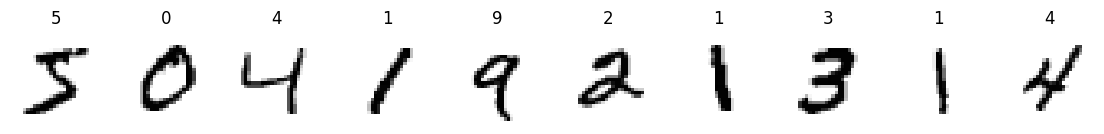

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
  ax.imshow(X_train[i], cmap="gray_r")
  ax.set_title(y_train[i])
  ax.axis("off")
plt.show()

## Data transformation

We need to transform this data:

1. Flatten the images: an array of shape `(_, 784)` rather than `(_, 28, 28)`, where `_` is the number of examples. Each image becomes a vector of 784 pixels, the input a `Dense` layer expects.
2. Bring the pixels into the $[0, 1]$ range rather than $[0, 255]$.
3. [One-hot](https://en.wikipedia.org/wiki/One-hot) encode the classes: the first of the two losses we will see, `categorical_crossentropy`, expects 10 values per example, all zero except for a 1 at the index of its class.

We keep `y_train` and `y_test`, and store the encoded classes in `Y_train` and `Y_test`.

In [5]:
nb_classes = 10
input_dim = 28 * 28

# "Flat" images: the network's input is a vector of input_dim pixels, in [0, 1].
# -1 lets NumPy compute the number of examples.
X_train = X_train.reshape(-1, input_dim) / 255
X_test = X_test.reshape(-1, input_dim) / 255

# The classes as one-hot vectors, for categorical_crossentropy
Y_train = keras.utils.to_categorical(y_train, num_classes=nb_classes)
Y_test = keras.utils.to_categorical(y_test, num_classes=nb_classes)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
print(f"Label {y_train[0]} one-hot encoded: {Y_train[0]}")

(60000, 784) (10000, 784) (60000, 10) (10000, 10)
Label 5 one-hot encoded: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Multinomial logistic regression

The first model has no hidden layer: a `keras.Input` of `input_dim` pixels, then a `layers.Dense` layer of `nb_classes` neurons, with the softmax activation. Each neuron computes a linear combination of the pixels, and the softmax turns them into 10 probabilities that sum to 1: this is a multinomial logistic regression.

In [6]:
model = keras.Sequential(
  [keras.Input(shape=(input_dim,)), layers.Dense(nb_classes, activation="softmax")]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

A `Dense` layer has one weight per input and per neuron, plus one bias per neuron: 784 × 10 + 10 = 7,850 parameters. `None` is the batch size, left free.

## Training

We compile the model with `compile`: the `"sgd"` optimizer (stochastic gradient descent, learning rate of 0.01), the `categorical_crossentropy` loss, which takes the one-hot targets `Y_train`, and the `"accuracy"` metric. Then we train it with `fit`, with:

- 128 examples per batch;
- 10 epochs;
- 20% of the training data for validation (`validation_split`).

Finally, the `evaluate` function measures its loss and accuracy on the test set. These numbers are the baseline for the next models.

In [7]:
def evaluate(model: keras.Model, one_hot: bool = False) -> None:
  """Print the loss and accuracy of `model` on the test set.

  one_hot: True for a model trained on the one-hot targets (Y_train).
  """
  loss, accuracy = model.evaluate(X_test, Y_test if one_hot else y_test, verbose=0)
  print(f"Test: loss {loss:.3f}, accuracy {accuracy:.3f}")

In [8]:
# compile attaches an optimizer, a loss function and metrics to the model
model.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

# fit trains the compiled model: a complete training loop
history = model.fit(X_train, Y_train, batch_size=128, epochs=10, validation_split=0.2)
evaluate(model, one_hot=True)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6740 - loss: 1.3776 - val_accuracy: 0.8325 - val_loss: 0.8860
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8336 - loss: 0.7852 - val_accuracy: 0.8615 - val_loss: 0.6519
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8521 - loss: 0.6389 - val_accuracy: 0.8725 - val_loss: 0.5588
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8619 - loss: 0.5686 - val_accuracy: 0.8791 - val_loss: 0.5073
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8687 - loss: 0.5256 - val_accuracy: 0.8841 - val_loss: 0.4740
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8738 - loss: 0.4960 - val_accuracy: 0.8875 - val_loss: 0.4504
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8778 - loss: 0.4740 - val_accuracy: 0.8902 - val_loss: 0.4325
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8805 - loss: 0.4569 - val_accuracy: 0.

The logistic regression reaches 89.6% validation accuracy at the last epoch, and 89.5% on the test set, with a test loss of 0.40.

## A loss for integer labels

The `sparse_categorical_crossentropy` loss computes the same cross-entropy, but from the integer labels `y_train`: one-hot encoding becomes unnecessary. Let's train `model2`, identical to the previous one, with this loss and the same settings.

In [9]:
model2 = keras.Sequential(
  [keras.Input(shape=(input_dim,)), layers.Dense(nb_classes, activation="softmax")]
)
model2.compile(
  optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
model2.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evaluate(model2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6708 - loss: 1.3834 - val_accuracy: 0.8277 - val_loss: 0.8895
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8303 - loss: 0.7897 - val_accuracy: 0.8570 - val_loss: 0.6536
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8513 - loss: 0.6410 - val_accuracy: 0.8697 - val_loss: 0.5592
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8629 - loss: 0.5693 - val_accuracy: 0.8773 - val_loss: 0.5071
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8692 - loss: 0.5256 - val_accuracy: 0.8818 - val_loss: 0.4734
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8742 - loss: 0.4956 - val_accuracy: 0.8863 - val_loss: 0.4495
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8778 - loss: 0.4733 - val_accuracy: 0.8888 - val_loss: 0.4316
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8810 - loss: 0.4560 - val_accuracy: 0.

The same results, up to random draws (initialization, batch order): only the format of the targets changes. Integer labels avoid storing 10 values per example.

## Regularized multilayer perceptron

The function `build_deep_model` returns a fresh, uncompiled multilayer perceptron:

- 4 hidden layers of 20 neurons, with the ReLU activation;
- on their weights, an L2 penalty with a coefficient of $10^{-4}$ (`kernel_regularizer`) and He initialization (`kernel_initializer`), suited to ReLU;
- the same softmax output layer as the logistic regression.

We create one, `deep_model`, compiled with the `"adam"` optimizer, the `sparse_categorical_crossentropy` loss and the accuracy, and trained with the same settings as the logistic regression. The next parts reuse `build_deep_model`.

In [10]:
def build_deep_model() -> keras.Model:
  """A fresh multilayer perceptron: 4 regularized hidden layers of 20 neurons."""
  hidden = dict(
    activation="relu",
    kernel_regularizer=keras.regularizers.L2(1e-4),
    kernel_initializer="he_normal",
  )
  return keras.Sequential(
    [
      keras.Input(shape=(input_dim,)),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(20, **hidden),
      layers.Dense(nb_classes, activation="softmax"),
    ],
    name="deep_model",
  )


deep_model = build_deep_model()
deep_model.summary()
deep_model.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
deep_model.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evaluate(deep_model)

Model: "deep_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,170 (67.07 KB)

 Trainable params: 17,170 (67.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7794 - loss: 0.7258 - val_accuracy: 0.9183 - val_loss: 0.3081
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9224 - loss: 0.2857 - val_accuracy: 0.9349 - val_loss: 0.2411
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9360 - loss: 0.2348 - val_accuracy: 0.9418 - val_loss: 0.2204
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9450 - loss: 0.2079 - val_accuracy: 0.9453 - val_loss: 0.2081
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9503 - loss: 0.1904 - val_accuracy: 0.9461 - val_loss: 0.2015
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9545 - loss: 0.1777 - val_accuracy: 0.9485 - val_loss: 0.1968
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9574 - loss: 0.1674 - val_accuracy: 0.9490 - val_loss: 0.1971
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9604 - loss: 0.1587 - val_accuracy: 0.

About 5 points more than the logistic regression (94.8% against 89.5% on the test set), for 17,170 parameters instead of 7,850. Part of the gain comes from Adam: the TensorBoard part compares the two optimizers on this model.

## Hyperparameter search

How many neurons in the hidden layer, which learning rate? KerasTuner tries combinations of hyperparameters and keeps the best one, scored on the validation set.

The function `build_model(hp)` returns a perceptron with one ReLU hidden layer, compiled with Adam, the `sparse_categorical_crossentropy` loss and the accuracy. It reads its hyperparameters from `hp`:

- `units`, the number of hidden neurons: from 32 to 512, in steps of 32;
- `learning_rate`, Adam's learning rate: from $10^{-4}$ to $10^{-2}$, on a logarithmic scale.

The search goes through `keras_tuner.BayesianOptimization`: objective `val_accuracy`, 5 trials, each trained 3 times for a less noisy average, 10 epochs per training, batches of 1,500 examples and 20% validation. This is the longest part: a few minutes on CPU.

In [11]:
def build_model(hp: keras_tuner.HyperParameters) -> keras.Model:
  # Each call to hp reads the value the tuner picked for the current trial
  units = hp.Int("units", min_value=32, max_value=512, step=32)
  learning_rate = hp.Float(
    "learning_rate", min_value=1e-4, max_value=1e-2, sampling="log"
  )
  model = keras.Sequential(
    [
      keras.Input(shape=(input_dim,)),
      layers.Dense(units, activation="relu"),
      layers.Dense(nb_classes, activation="softmax"),
    ]
  )
  model.compile(
    optimizer=keras.optimizers.Adam(learning_rate),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
  )
  return model


tuner = keras_tuner.BayesianOptimization(
  build_model,
  objective="val_accuracy",
  max_trials=5,
  executions_per_trial=3,
  seed=0,
  directory="tuner",
  project_name="mnist",
  overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 2
units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [12]:
tuner.search(X_train, y_train, epochs=10, batch_size=1500, validation_split=0.2)

Trial 5 Complete [00h 00m 25s]
val_accuracy: 0.930472215016683

Best val_accuracy So Far: 0.94563889503479
Total elapsed time: 00h 03m 39s


In [13]:
tuner.results_summary()
best_model = tuner.get_best_models()[0]
best_model.summary()
evaluate(best_model)

Results summary
Results in tuner/mnist
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
units: 352
learning_rate: 0.0003076479630142435
Score: 0.94563889503479

Trial 2 summary
Hyperparameters:
units: 512
learning_rate: 0.00020263128279152088
Score: 0.941361129283905

Trial 3 summary
Hyperparameters:
units: 448
learning_rate: 0.0001906261608057756
Score: 0.9375277757644653

Trial 4 summary
Hyperparameters:
units: 128
learning_rate: 0.0003187720102714487
Score: 0.930472215016683

Trial 1 summary
Hyperparameters:
units: 96
learning_rate: 0.000254400127046171
Score: 0.9194166858990988


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 352)            │       276,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,850 (1.07 MB)

 Trainable params: 279,850 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Test: loss 0.206, accuracy 0.943


The best trial (352 neurons, a learning rate of $3 \times 10^{-4}$) reaches 94.6% in validation and 94.3% on the test set, less than `deep_model` (94.8%), with 279,850 parameters instead of 17,170. With 10 epochs and batches of 1,500 examples, each training only takes 320 steps.

When it runs, `get_best_models` warns that it doesn't reload the optimizer's state (`Skipping variable loading for optimizer`): the model's weights are there, and they are enough to evaluate it.

## Adam against SGD in TensorBoard

TensorBoard displays the learning curves that a [`keras.callbacks.TensorBoard`](https://keras.io/api/callbacks/tensorboard/) callback, passed to `fit`, writes into a directory: one subdirectory per training.

We train two fresh multilayer perceptrons (`build_deep_model()`) with the settings of the "Regularized multilayer perceptron" part, one with the `"adam"` optimizer, the other with `"sgd"`. Each `fit` gets a callback that writes into `logs/adam` for the first one, into `logs/sgd` for the second one.

In [14]:
for optimizer in ["adam", "sgd"]:
  model = build_deep_model()
  model.compile(
    optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"]
  )
  tensorboard = keras.callbacks.TensorBoard(log_dir=f"logs/{optimizer}")
  model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2,
    callbacks=[tensorboard],
  )

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7577 - loss: 0.7623 - val_accuracy: 0.9154 - val_loss: 0.3125
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9206 - loss: 0.2907 - val_accuracy: 0.9314 - val_loss: 0.2487
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9348 - loss: 0.2388 - val_accuracy: 0.9392 - val_loss: 0.2217
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9429 - loss: 0.2091 - val_accuracy: 0.9433 - val_loss: 0.2081
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9497 - loss: 0.1877 - val_accuracy: 0.9463 - val_loss: 0.2016
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9550 - loss: 0.1724 - val_accuracy: 0.9489 - val_loss: 0.1966
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9589 - loss: 0.1605 - val_accuracy: 0.9505 - val_loss: 0.1911
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9622 - loss: 0.1508 - val_accuracy: 0.

The next cell opens the dashboard, which only shows in a running session: run the notebook to see it.

In [15]:
%load_ext tensorboard
%tensorboard --logdir logs

In the *Scalars* tab, the `epoch_loss` and `epoch_accuracy` curves overlay the two trainings; `train` and `validation` separate the training and validation curves.

They show what the `fit` logs above say: Adam converges much faster. It exceeds 90% validation accuracy from the first epoch on (91.5%) and ends at 95.3%, while SGD only gets there at the fifth epoch and ends at 92.4%. SGD multiplies the gradient of each weight by the same learning rate (0.01); Adam adapts each weight's step to the size of its recent gradients, and keeps a momentum from one step to the next (the average of the gradients).

## Early stopping and saving the best model

Rather than setting the number of epochs in advance, we stop the training when the validation loss no longer decreases, and keep the best model seen.

We train a fresh multilayer perceptron with Adam, for at most 50 epochs, with two callbacks:

- `keras.callbacks.EarlyStopping`: stop after 3 epochs without a decrease of `val_loss`, and go back to the weights of the best epoch;
- `keras.callbacks.ModelCheckpoint`: save the model into `best.keras`, each time `val_loss` reaches a new minimum.

We display the number of epochs run, then compare on the test set the model in memory and the model reloaded with `keras.models.load_model`.

In [16]:
# Reset the seed before drawing the weights: earlier cells no longer matter
keras.utils.set_random_seed(0)
model = build_deep_model()
model.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
callbacks = [
  # Stop after 3 epochs without a decrease of val_loss, best epoch's weights restored
  keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
  ),
  # Save the model at each new minimum of val_loss
  keras.callbacks.ModelCheckpoint(
    "best.keras", monitor="val_loss", save_best_only=True
  ),
]
history = model.fit(
  X_train,
  y_train,
  batch_size=128,
  epochs=50,
  validation_split=0.2,
  callbacks=callbacks,
)
print(f"Epochs run: {len(history.history['loss'])}")

evaluate(model)
best_model = keras.models.load_model("best.keras")
evaluate(best_model)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7685 - loss: 0.7334 - val_accuracy: 0.9172 - val_loss: 0.3085
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9246 - loss: 0.2793 - val_accuracy: 0.9379 - val_loss: 0.2338
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9400 - loss: 0.2253 - val_accuracy: 0.9438 - val_loss: 0.2139
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9469 - loss: 0.1983 - val_accuracy: 0.9458 - val_loss: 0.2044
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9525 - loss: 0.1798 - val_accuracy: 0.9463 - val_loss: 0.2003
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9564 - loss: 0.1664 - val_accuracy: 0.9482 - val_loss: 0.1988
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9590 - loss: 0.1561 - val_accuracy: 0.9470 - val_loss: 0.2014
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9616 - loss: 0.1485 - val_accuracy: 0.

Training stops at epoch 14, 3 epochs after the minimum of `val_loss` (epoch 11). The model in memory and the reloaded model give the same numbers: `restore_best_weights` puts back into the model the weights of the best epoch, the one `ModelCheckpoint` saved last. Without it, the model in memory would keep the weights of the last epoch, 3 epochs after the best one.